# Dragon Egg notebook 

## Objectif
explorer et nettoyer les données, prédire le clan (`clan_dragon`), estimer l’énergie arcanique (`energie_arcanique`), détecter des observations atypiques et comparer les méthodes. Les résultats des modèles sont calculés lors de l’exécution : aucun score n’est inventé.

## 1. Imports et paramètres

In [4]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, IsolationForest
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, LocalOutlierFactor
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
print("Imports prêts")

Imports prêts


## 2. Chargement du fichier
Le fichier utilisé pendant l’exploration s’appelait `dragons..csv`. Si son nom est différent, modifiez `DATA_PATH`. On conserve les données brutes pour comparer avant/après.

In [5]:
DATA_PATH = Path("dragons..csv")
if not DATA_PATH.exists():
    candidats = sorted(Path(".").glob("*.csv"))
    print("Fichier indiqué introuvable. CSV trouvés :", [p.name for p in candidats])
    if len(candidats) == 1:
        DATA_PATH = candidats[0]
        print("Utilisation du fichier :", DATA_PATH)
    else:
        raise FileNotFoundError("Placez le CSV dans le dossier du notebook ou modifiez DATA_PATH.")
df_brut = pd.read_csv(DATA_PATH, sep=None, engine="python")
df = df_brut.copy()
print(f"Dimensions initiales : {df.shape[0]} lignes × {df.shape[1]} colonnes")
display(df.head())

Dimensions initiales : 607 lignes × 7 colonnes


,﻿id_oeuf,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz,clan_dragon
0,SYN-0424,75.4,54.9,67.0,6.8,17.0,Feu
1,SYN-0354,32.2,72.9,39.6,3.95,9.2,Glace
2,SYN-0032,58.0,58.0,92.6,5.96,25.4,Foudre
3,SYN-0300,30.0,78.8,61.5,6.17,8.7,Glace
4,SYN-0409,82.1,20.8,86.5,4.71,22.7,Feu


## 3. Exploration initiale

### 3.1 Structure et types
L’exploration précédente a trouvé 607 lignes et 7 colonnes. Seule l’humidité est reconnue comme numérique ; température, énergie, poids et vibrations sont de type texte. Les statistiques de ces quatre mesures ne sont donc pas interprétables numériquement avant conversion.

In [6]:
print("Dimensions :", df.shape)
print("Noms exacts :")
for c in df.columns: print(repr(c))
print("\nTypes et valeurs non nulles :")
df.info()
print("\nStatistiques descriptives :")
display(df.describe(include="all").T)

Dimensions : (607, 7)
Noms exacts :
'\ufeffid_oeuf'
'temperature_nid_c'
'humidite_nid_pct'
'energie_arcanique'
'poids_oeuf_kg'
'vibration_coquille_hz'
'clan_dragon'

Types et valeurs non nulles :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ﻿id_oeuf               605 non-null    object 
 1   temperature_nid_c      607 non-null    object 
 2   humidite_nid_pct       603 non-null    float64
 3   energie_arcanique      606 non-null    object 
 4   poids_oeuf_kg          606 non-null    object 
 5   vibration_coquille_hz  604 non-null    object 
 6   clan_dragon            606 non-null    object 
dtypes: float64(1), object(6)
memory usage: 33.3+ KB

Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
﻿id_oeuf,605,598,SYN-0469,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_nid_c,607,393,49.9,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
humidite_nid_pct,603.0,NaN,NaN,NaN,52.313267,18.785743,-7.0,36.95,48.0,70.6,100.0
energie_arcanique,606,363,100.0,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poids_oeuf_kg,606,289,4.48,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vibration_coquille_hz,604,240,21.3,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clan_dragon,606,9,Feu,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.2 Valeurs manquantes et doublons
L’exploration initiale a identifié 12 cellules manquantes : humidité (4), vibrations (3), identifiant (2), poids (1), énergie (1) et clan (1). Sept lignes étaient entièrement dupliquées. Les doublons complets sont distincts des identifiants répétés : ces derniers seront inspectés, pas supprimés automatiquement.

In [7]:
display(pd.DataFrame({"nb_manquants": df.isna().sum(), "pourcentage": (df.isna().mean()*100).round(2)}).sort_values("nb_manquants", ascending=False))
print("Doublons de lignes complètes :", int(df.duplicated().sum()))
for c in df.columns:
    print(f"\n--- {repr(c)} : {df[c].nunique(dropna=False)} valeurs distinctes ---")
    display(df[c].value_counts(dropna=False).head(15).to_frame("effectif"))

,nb_manquants,pourcentage
humidite_nid_pct,4,0.66
vibration_coquille_hz,3,0.49
﻿id_oeuf,2,0.33
poids_oeuf_kg,1,0.16
energie_arcanique,1,0.16
clan_dragon,1,0.16
temperature_nid_c,0,0.00


Doublons de lignes complètes : 7

--- '\ufeffid_oeuf' : 599 valeurs distinctes ---


,effectif
﻿id_oeuf,
SYN-0199,2
SYN-0457,2
SYN-0010,2
SYN-0469,2
SYN-0241,2
SYN-0365,2
NaN,2
SYN-0510,2
SYN-0214,1



--- 'temperature_nid_c' : 393 valeurs distinctes ---


,effectif
temperature_nid_c,
49.9,5
28.2,5
24.4,4
80.7,4
32.9,4
54.6,4
22.4,4
77.7,4
49.5,4



--- 'humidite_nid_pct' : 370 valeurs distinctes ---


... (5 outputs left out)


--- 'vibration_coquille_hz' : 241 valeurs distinctes ---


,effectif
vibration_coquille_hz,
21.3,8
14.2,8
17.0,7
10.9,7
19.6,7
8.4,6
12.4,6
10.0,6
12.7,6



--- 'clan_dragon' : 10 valeurs distinctes ---


,effectif
clan_dragon,
Feu,202
Foudre,198
Glace,197
GLACE,3
Foudre,2
feu,1
glace,1
FEU,1
foudre,1


### 3.3 Distribution et anomalies repérées
Avant conversion, seule `humidite_nid_pct` est numérique : moyenne 52,31 %, médiane 48 %, écart-type 18,79, minimum −7 % et maximum 100 %. L’IQR ne repère aucune valeur extrême pour cette variable (bornes −13,525 à 121,075), mais −7 % reste impossible pour une humidité en pourcentage. Une vibration de −5 Hz a également été repérée. Les limites métier sont donc nécessaires en complément de l’IQR. Aucune borne arbitraire ne sera inventée pour la température ou l’énergie.

Colonnes numériques reconnues : ['humidite_nid_pct']


,count,mean,std,min,25%,50%,75%,max
humidite_nid_pct,603.0,52.313267,18.785743,-7.0,36.95,48.0,70.6,100.0


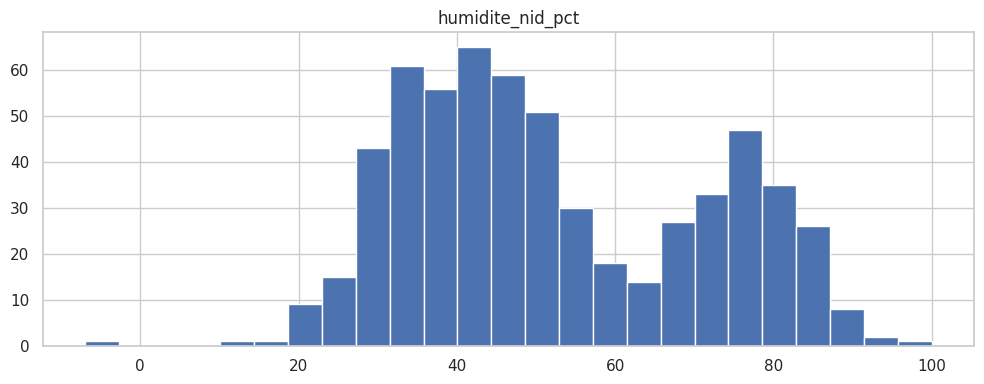

,colonne,Q1,Q3,IQR,borne_basse,borne_haute,candidats
0,humidite_nid_pct,36.95,70.6,33.65,-13.525,121.075,0


Humidité hors [0,100] : 1


In [8]:
num_cols_initiales = df.select_dtypes(include=np.number).columns.tolist()
print("Colonnes numériques reconnues :", num_cols_initiales)
if num_cols_initiales:
    display(df[num_cols_initiales].describe().T)
    df[num_cols_initiales].hist(figsize=(10,4), bins=25); plt.tight_layout(); plt.show()
rows=[]
for c in num_cols_initiales:
    s=df[c].dropna()
    if len(s)<4: continue
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr
    rows.append({"colonne":c,"Q1":q1,"Q3":q3,"IQR":iqr,"borne_basse":lo,"borne_haute":hi,"candidats":int(((s<lo)|(s>hi)).sum())})
display(pd.DataFrame(rows))
print("Humidité hors [0,100] :", int(((pd.to_numeric(df["humidite_nid_pct"], errors="coerce")<0)|(pd.to_numeric(df["humidite_nid_pct"], errors="coerce")>100)).sum()))

L’exploration initiale a trouvé 607 lignes et 7 colonnes, un caractère invisible dans le nom `id_oeuf`, des mesures numériques importées comme texte, 12 cellules manquantes, 7 doublons complets, plusieurs variantes de casse des clans, une humidité de −7 % et une vibration de −5 Hz. Ces constats motivent les décisions ci-dessous.

## 4. Nettoyage et décisions justifiées

- Retirer le caractère invisible (`\ufeff`) et les espaces des noms de colonnes.
- Supprimer uniquement les lignes entièrement identiques (7 détectées initialement).
- Convertir les cinq mesures en nombres, y compris si une virgule décimale apparaît.
- Harmoniser les variantes de casse des clans en `Feu`, `Foudre` et `Glace`.
- Transformer l’humidité hors de [0, 100] et les poids/vibrations négatifs en valeurs manquantes : on ne connaît pas leur vraie valeur, donc on ne remplace pas par zéro.
- Garder les autres valeurs manquantes jusqu’à la préparation des modèles. Les imputations seront ajustées uniquement sur l’entraînement via des pipelines.
- Conserver les identifiants répétés pour les inspecter, mais ne jamais les utiliser comme variables prédictives.

In [9]:
df_prepare = df_brut.copy()
df_prepare.columns = df_prepare.columns.astype(str).str.replace("\ufeff", "", regex=False).str.strip().str.lower()
for c in df_prepare.select_dtypes(include=["object", "string"]).columns:
    df_prepare[c] = df_prepare[c].map(lambda x: x.strip() if isinstance(x,str) else x)
doublons_supprimes = int(df_prepare.duplicated().sum())
df_prepare = df_prepare.drop_duplicates().copy()

NUM_COLS = ["temperature_nid_c", "humidite_nid_pct", "energie_arcanique", "poids_oeuf_kg", "vibration_coquille_hz"]
for c in NUM_COLS:
    txt = df_prepare[c].astype("string").str.strip().str.replace(",", ".", regex=False)
    df_prepare[c] = pd.to_numeric(txt, errors="coerce")
df_prepare["clan_dragon"] = (df_prepare["clan_dragon"].astype("string").str.strip().str.casefold().map({"feu":"Feu", "foudre":"Foudre", "glace":"Glace"}))
df_prepare.loc[~df_prepare["humidite_nid_pct"].between(0,100), "humidite_nid_pct"] = np.nan
for c in ["poids_oeuf_kg", "vibration_coquille_hz"]:
    df_prepare.loc[df_prepare[c] < 0, c] = np.nan
print("Doublons complets supprimés :", doublons_supprimes)
print("Dimensions après nettoyage :", df_prepare.shape)
print("\nTypes :"); display(df_prepare.dtypes.to_frame("type"))
print("\nValeurs manquantes :"); display(pd.DataFrame({"nombre":df_prepare.isna().sum(),"pct":(df_prepare.isna().mean()*100).round(2)}))
print("\nClans après harmonisation :"); display(df_prepare["clan_dragon"].value_counts(dropna=False).to_frame("effectif"))
print("\nIdentifiants répétés :")
display(df_prepare.loc[df_prepare["id_oeuf"].notna() & df_prepare["id_oeuf"].duplicated(keep=False)].sort_values("id_oeuf"))
print("Valeurs négatives restantes :", {c:int((df_prepare[c]<0).sum()) for c in ["humidite_nid_pct","poids_oeuf_kg","vibration_coquille_hz"]})

Doublons complets supprimés : 7
Dimensions après nettoyage : (600, 7)

Types :


,type
id_oeuf,object
temperature_nid_c,Float64
humidite_nid_pct,Float64
energie_arcanique,Float64
poids_oeuf_kg,Float64
vibration_coquille_hz,Float64
clan_dragon,object



Valeurs manquantes :


,nombre,pct
id_oeuf,2,0.33
temperature_nid_c,0,0.00
humidite_nid_pct,4,0.67
energie_arcanique,1,0.17
poids_oeuf_kg,1,0.17
vibration_coquille_hz,4,0.67
clan_dragon,1,0.17



Clans après harmonisation :


,effectif
clan_dragon,
Glace,200
Foudre,200
Feu,199
NaN,1



Identifiants répétés :


,id_oeuf,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz,clan_dragon


Valeurs négatives restantes : {'humidite_nid_pct': 0, 'poids_oeuf_kg': 0, 'vibration_coquille_hz': 0}


### 4.1 Rapport de qualité avant/après
Le tableau ci-dessous vérifie les changements réellement produits. Les valeurs manquantes peuvent augmenter après correction de valeurs physiquement impossibles : c’est attendu, car ces mesures ne sont pas fiables et seront imputées dans les modèles si elles sont des variables explicatives.

In [10]:
df_brut_noms=df_brut.copy(); df_brut_noms.columns=df_brut_noms.columns.astype(str).str.replace("\ufeff","",regex=False).str.strip().str.lower()
rapport_qualite=pd.DataFrame([
 {"indicateur":"Lignes","avant":len(df_brut_noms),"apres":len(df_prepare)},
 {"indicateur":"Colonnes","avant":df_brut_noms.shape[1],"apres":df_prepare.shape[1]},
 {"indicateur":"Doublons complets","avant":int(df_brut_noms.duplicated().sum()),"apres":int(df_prepare.duplicated().sum())},
 {"indicateur":"Cellules manquantes","avant":int(df_brut_noms.isna().sum().sum()),"apres":int(df_prepare.isna().sum().sum())},
])
display(rapport_qualite)

,indicateur,avant,apres
0,Lignes,607,600
1,Colonnes,7,7
2,Doublons complets,7,0
3,Cellules manquantes,12,13


## 5. Analyse exploratoire après nettoyage

### 5.1 Statistiques et distributions
Les mesures sont maintenant numériques. Les histogrammes permettent d’observer les distributions et d’identifier des valeurs à examiner ; une valeur rare n’est pas automatiquement une erreur.

,count,mean,std,min,25%,50%,75%,max
temperature_nid_c,600.0,52.7995,20.668146,-18.0,33.575,52.15,71.825,135.0
humidite_nid_pct,596.0,52.507886,18.679974,13.8,37.15,48.0,71.125,100.0
energie_arcanique,599.0,74.939399,17.671432,25.4,61.55,77.5,87.8,180.0
poids_oeuf_kg,599.0,5.007629,1.609218,2.2,4.38,4.88,5.51,38.0
vibration_coquille_hz,596.0,17.92651,15.065289,4.0,11.5,16.85,22.7,250.0


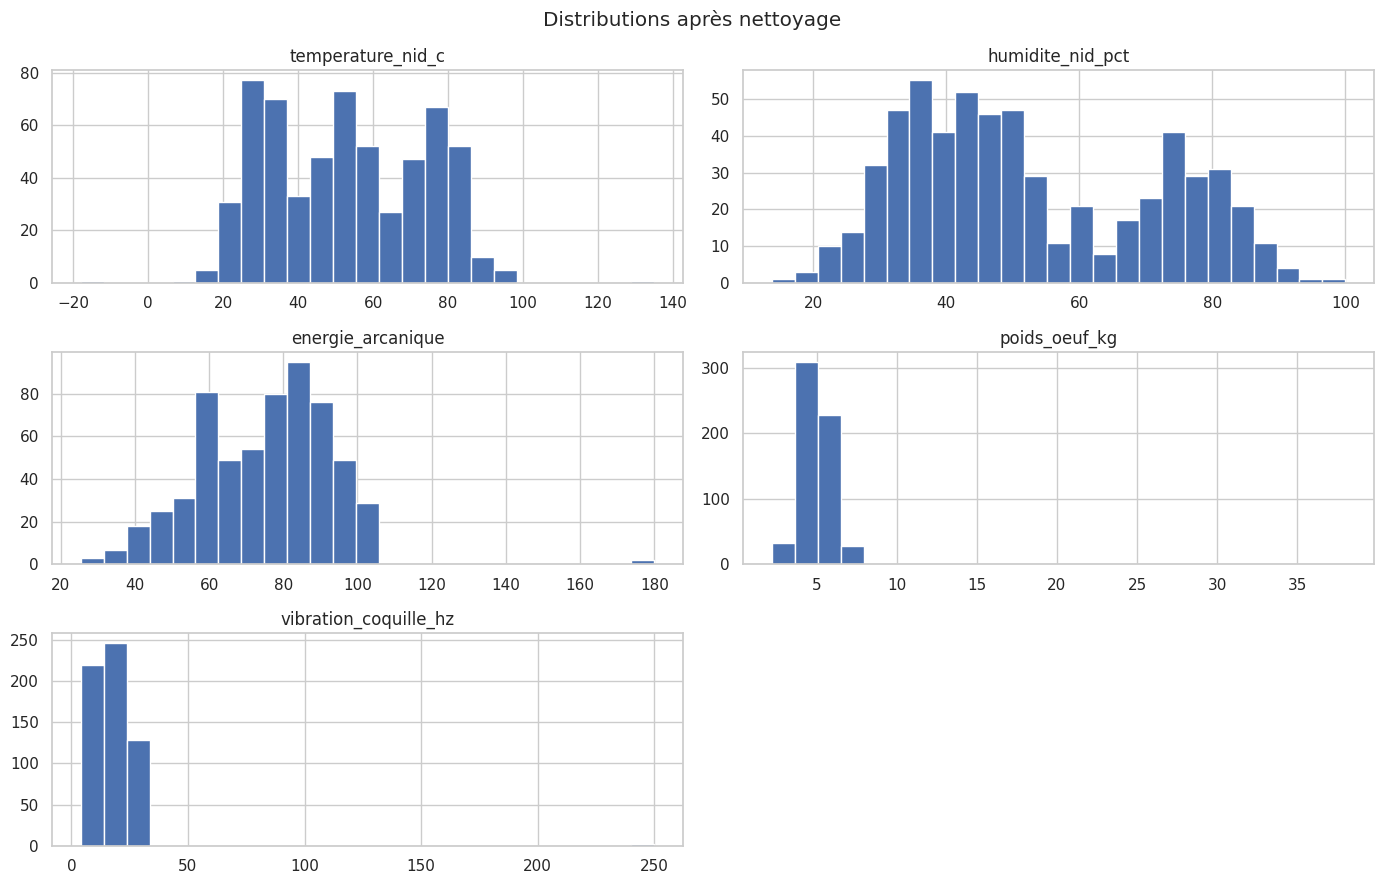

In [11]:
display(df_prepare[NUM_COLS].describe().T)
df_prepare[NUM_COLS].hist(figsize=(14,9), bins=25); plt.suptitle("Distributions après nettoyage"); plt.tight_layout(); plt.show()

### 5.2 Répartition des clans
Les variations de casse ont été regroupées. La classe manquante reste identifiée comme inconnue et ne sera pas utilisée comme cible de classification.

,effectif
clan_dragon,
Glace,200
Foudre,200
Feu,199
NaN,1


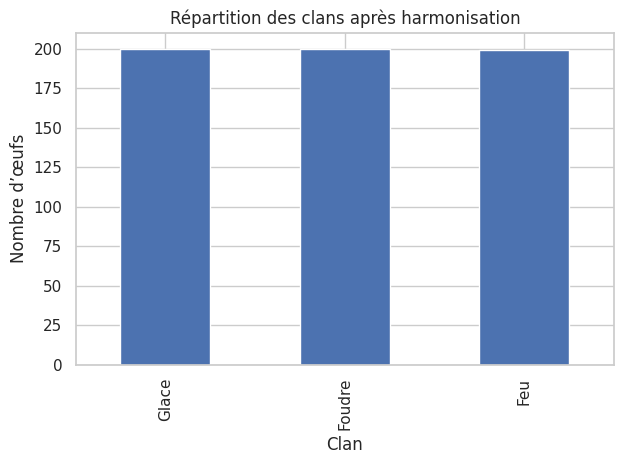

In [12]:
display(df_prepare["clan_dragon"].value_counts(dropna=False).to_frame("effectif"))
df_prepare["clan_dragon"].value_counts().plot(kind="bar")
plt.title("Répartition des clans après harmonisation"); plt.xlabel("Clan"); plt.ylabel("Nombre d’œufs"); plt.tight_layout(); plt.show()

### 5.3 Corrélations
La corrélation mesure une association linéaire et ne prouve pas une causalité. Elle sert ici à explorer les relations possibles entre les mesures.

,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz
temperature_nid_c,1.000000,-0.813917,0.548477,0.285083,0.142506
humidite_nid_pct,-0.813917,1.000000,-0.622722,-0.240090,-0.240958
energie_arcanique,0.548477,-0.622722,1.000000,0.118489,0.242129
poids_oeuf_kg,0.285083,-0.240090,0.118489,1.000000,0.050066
vibration_coquille_hz,0.142506,-0.240958,0.242129,0.050066,1.000000


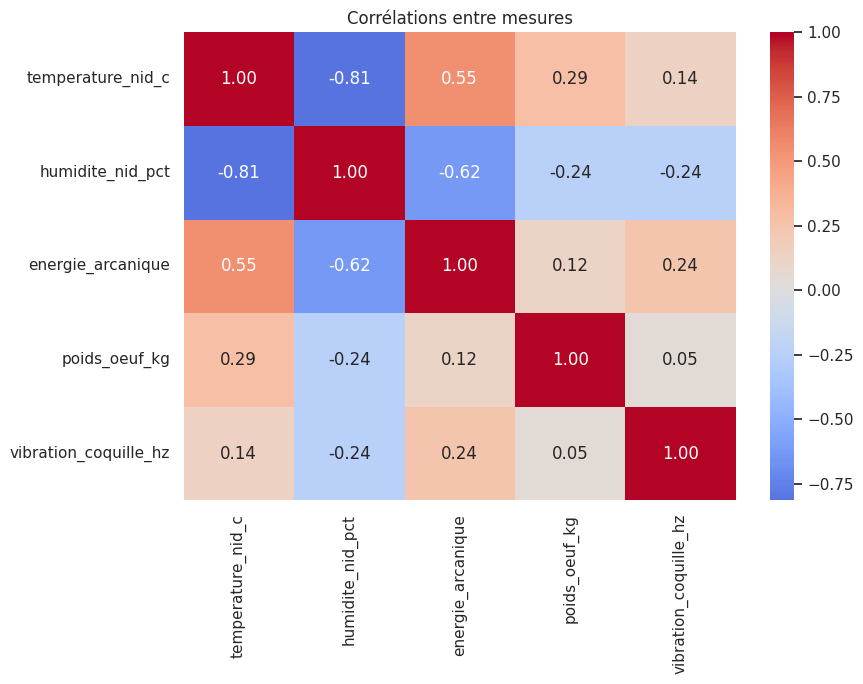

In [13]:
corr=df_prepare[NUM_COLS].corr()
display(corr)
plt.figure(figsize=(9,7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Corrélations entre mesures"); plt.tight_layout(); plt.show()

### 5.4 Valeurs extrêmes selon l’IQR
L’IQR signale des candidates à l’examen, et non des erreurs confirmées. Les règles métier (par exemple humidité entre 0 et 100 %) restent prioritaires.

In [14]:
iqr_rows=[]
for c in NUM_COLS:
    s=df_prepare[c].dropna()
    if len(s)<4: continue
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr
    iqr_rows.append({"variable":c,"Q1":q1,"Q3":q3,"borne_basse":lo,"borne_haute":hi,"candidats":int(((s<lo)|(s>hi)).sum())})
display(pd.DataFrame(iqr_rows))

,variable,Q1,Q3,borne_basse,borne_haute,candidats
0,temperature_nid_c,33.575,71.825,-23.8000,129.2000,1
1,humidite_nid_pct,37.150,71.125,-13.8125,122.0875,0
2,energie_arcanique,61.550,87.800,22.1750,127.1750,2
3,poids_oeuf_kg,4.380,5.510,2.6850,7.2050,8
4,vibration_coquille_hz,11.500,22.700,-5.3000,39.5000,2


# 5.5 — Vérification des valeurs manquantes après nettoyage

In [ ]:
manquantes = df_prepare.isna().sum()

print("Valeurs manquantes par colonne :")
display(manquantes.to_frame(name="nombre"))

print(f"Total de cellules manquantes : {manquantes.sum()}")

# Afficher les lignes qui contiennent au moins une valeur manquante
lignes_incompletes = df_prepare[df_prepare.isna().any(axis=1)]

print(f"Nombre de lignes contenant au moins une valeur manquante : {len(lignes_incompletes)}")
display(lignes_incompletes)

Valeurs manquantes par colonne :


,nombre
id_oeuf,2
temperature_nid_c,0
humidite_nid_pct,4
energie_arcanique,1
poids_oeuf_kg,1
vibration_coquille_hz,4
clan_dragon,1


Total de cellules manquantes : 13
Nombre de lignes contenant au moins une valeur manquante : 13


,id_oeuf,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz,clan_dragon
50,SYN-0105,33.6,<NA>,44.2,5.01,14.1,Glace
61,NaN,36.5,76.0,58.0,4.38,10.9,Glace
65,SYN-0162,33.5,79.6,59.0,4.13,<NA>,Glace
90,SYN-0298,77.4,41.1,87.4,6.18,<NA>,Feu
101,SYN-0502,86.2,35.9,<NA>,5.13,14.5,Feu
300,SYN-0186,30.9,<NA>,62.5,4.67,10.0,Glace
357,NaN,20.8,81.1,54.8,4.96,4.9,Glace
443,SYN-0029,60.8,56.1,83.8,5.47,<NA>,Foudre
456,SYN-0208,75.6,27.5,95.2,6.65,<NA>,Feu
467,SYN-0365,54.6,<NA>,81.8,4.87,22.2,Foudre


# 5.6 — Inspection des valeurs atypiques avec la méthode IQR

In [ ]:
# Inspection des valeurs atypiques avec la méthode IQR

resultats_iqr = []

for colonne in NUM_COLS:
    serie = df_prepare[colonne].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr

    atypiques = df_prepare[
        df_prepare[colonne].notna()
        & (
            (df_prepare[colonne] < borne_basse)
            | (df_prepare[colonne] > borne_haute)
        )
    ]

    resultats_iqr.append({
        "variable": colonne,
        "borne_basse": borne_basse,
        "borne_haute": borne_haute,
        "nombre_atypiques": len(atypiques)
    })

    print(f"\n{colonne} : {len(atypiques)} valeur(s) atypique(s)")
    display(atypiques[["id_oeuf", colonne]])

tableau_iqr = pd.DataFrame(resultats_iqr)

print("\nSynthèse des valeurs atypiques :")
display(tableau_iqr)



temperature_nid_c : 1 valeur(s) atypique(s)


,id_oeuf,temperature_nid_c
254,SYN-0412,135.0



humidite_nid_pct : 0 valeur(s) atypique(s)


,id_oeuf,humidite_nid_pct



energie_arcanique : 2 valeur(s) atypique(s)


,id_oeuf,energie_arcanique
309,OEUF-068,180.0
511,SYN-0167,180.0


... (2 outputs left out)


vibration_coquille_hz : 2 valeur(s) atypique(s)


,id_oeuf,vibration_coquille_hz
253,SYN-0397,250.0
597,OEUF-057,250.0



Synthèse des valeurs atypiques :


,variable,borne_basse,borne_haute,nombre_atypiques
0,temperature_nid_c,-23.8000,129.2000,1
1,humidite_nid_pct,-13.8125,122.0875,0
2,energie_arcanique,22.1750,127.1750,2
3,poids_oeuf_kg,2.6850,7.2050,8
4,vibration_coquille_hz,-5.3000,39.5000,2


### 5.7 — Bilan de l'exploration des valeurs atypiques

L'analyse par la méthode de l'écart interquartile (IQR) a permis d'identifier plusieurs valeurs atypiques dans les variables numériques.

- **Température :** une valeur de 135 °C a été détectée.
- **Humidité :** aucune valeur atypique n'a été détectée par la méthode IQR après correction des valeurs hors limites.
- **Énergie arcanique :** deux observations présentent une valeur de 180.
- **Poids de l'œuf :** sept observations sont identifiées comme atypiques, dont une valeur particulièrement élevée de 38 kg.
- **Vibrations de la coquille :** deux observations présentent une valeur de 250 Hz.

Ces valeurs ne sont pas supprimées automatiquement. Certaines peuvent correspondre à des anomalies réelles, ce qui est particulièrement intéressant pour la future détection non supervisée des anomalies.

Les valeurs manquantes seront traitées lors de la préparation des données pour la modélisation. Les identifiants ne seront pas utilisés comme variables explicatives.

## 6. Classification : prédire le clan

La cible est `clan_dragon` et les prédicteurs sont les cinq mesures physiques. `id_oeuf` est exclu. Les lignes dont le clan est manquant sont exclues de cette tâche uniquement. Une séparation 80/20 stratifiée préserve la représentation des classes. Les modèles comparés : DummyClassifier, régression logistique, arbre, forêt aléatoire, KNN et SVM. Le F1 macro donne un poids égal à chaque classe ; accuracy, précision/rappel macro et matrice de confusion complètent l’analyse. L’imputation et la standardisation sont ajustées dans chaque pipeline, sur l’entraînement uniquement.

In [17]:
print("df_prepare existe :", "df_prepare" in globals())

if "df_prepare" in globals():
    print("Dimensions :", df_prepare.shape)
    print("\nColonnes :")
    print(df_prepare.columns.tolist())

    print("\nTypes :")
    print(df_prepare.dtypes)

    print("\nRépartition des clans :")
    print(df_prepare["clan_dragon"].value_counts(dropna=False))

df_prepare existe : True
Dimensions : (600, 7)

Colonnes :
['id_oeuf', 'temperature_nid_c', 'humidite_nid_pct', 'energie_arcanique', 'poids_oeuf_kg', 'vibration_coquille_hz', 'clan_dragon']

Types :
id_oeuf                   object
temperature_nid_c        Float64
humidite_nid_pct         Float64
energie_arcanique        Float64
poids_oeuf_kg            Float64
vibration_coquille_hz    Float64
clan_dragon               object
dtype: object

Répartition des clans :
clan_dragon
Glace     200
Foudre    200
Feu       199
NaN         1
Name: count, dtype: int64


Observations avec clan connu : 599


,effectif
clan_dragon,
Glace,200
Foudre,200
Feu,199


,modele,accuracy,precision_macro,rappel_macro,f1_macro,temps_s
0,KNN,0.983333,0.984127,0.983333,0.983323,0.116185
1,Forêt aléatoire,0.983333,0.984127,0.983333,0.983323,4.867429
2,SVM RBF,0.983333,0.984127,0.983333,0.983323,0.165897
3,Régression logistique,0.975000,0.975580,0.975000,0.974992,0.948430
4,Arbre de décision,0.966667,0.967643,0.966667,0.966862,0.311668
5,Dummy majoritaire,0.333333,0.111111,0.333333,0.166667,0.854221


Meilleur selon F1 macro test : KNN
              precision    recall  f1-score   support

         Feu       0.95      1.00      0.98        40
      Foudre       1.00      0.95      0.97        40
       Glace       1.00      1.00      1.00        40

    accuracy                           0.98       120
   macro avg       0.98      0.98      0.98       120
weighted avg       0.98      0.98      0.98       120



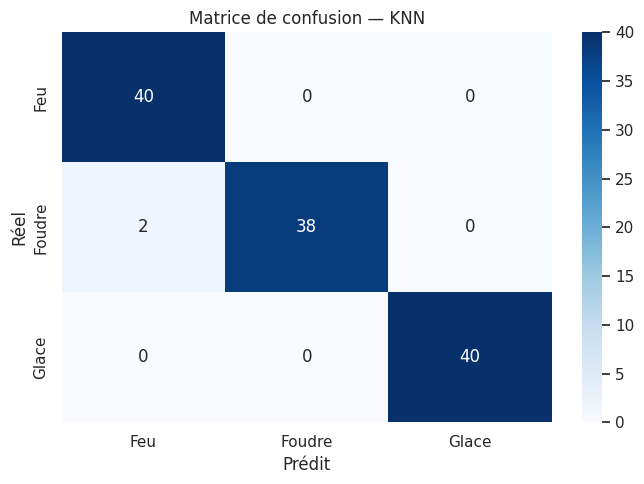

In [18]:
FEATURES_CLF=["temperature_nid_c","humidite_nid_pct","energie_arcanique","poids_oeuf_kg","vibration_coquille_hz"]
df_clf=df_prepare.dropna(subset=["clan_dragon"]).copy(); X=df_clf[FEATURES_CLF]; y=df_clf["clan_dragon"]
print("Observations avec clan connu :",len(y)); display(y.value_counts().to_frame("effectif"))
if y.nunique()<2 or y.value_counts().min()<2: raise ValueError("Pas assez d'observations par classe pour une séparation stratifiée.")
X_train_c,X_test_c,y_train_c,y_test_c=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE,stratify=y)
classifiers={
 "Dummy majoritaire":DummyClassifier(strategy="most_frequent"),
 "Régression logistique":LogisticRegression(max_iter=2000,random_state=RANDOM_STATE),
 "Arbre de décision":DecisionTreeClassifier(random_state=RANDOM_STATE,min_samples_leaf=3),
 "Forêt aléatoire":RandomForestClassifier(n_estimators=250,random_state=RANDOM_STATE,min_samples_leaf=2,n_jobs=-1),
 "KNN":KNeighborsClassifier(n_neighbors=7),
 "SVM RBF":SVC(kernel="rbf")
}
clf_models={}; clf_preds={}; rows=[]
for name,est in classifiers.items():
    pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("model",est)])
    t=time.perf_counter(); pipe.fit(X_train_c,y_train_c); duration=time.perf_counter()-t
    pred=pipe.predict(X_test_c); clf_models[name]=pipe; clf_preds[name]=pred
    rows.append({"modele":name,"accuracy":accuracy_score(y_test_c,pred),"precision_macro":precision_score(y_test_c,pred,average="macro",zero_division=0),"rappel_macro":recall_score(y_test_c,pred,average="macro",zero_division=0),"f1_macro":f1_score(y_test_c,pred,average="macro",zero_division=0),"temps_s":duration})
classification_results_df=pd.DataFrame(rows).sort_values("f1_macro",ascending=False).reset_index(drop=True)
display(classification_results_df)
meilleur_clf_nom=classification_results_df.iloc[0]["modele"]; pred_best=clf_preds[meilleur_clf_nom]
print("Meilleur selon F1 macro test :",meilleur_clf_nom); print(classification_report(y_test_c,pred_best,zero_division=0))
labels=sorted(y.unique()); cm=confusion_matrix(y_test_c,pred_best,labels=labels)
plt.figure(figsize=(7,5)); sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=labels,yticklabels=labels); plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion — "+meilleur_clf_nom); plt.tight_layout(); plt.show()

### Interprétation des résultats de classification

Les modèles de classification obtiennent de très bonnes performances pour prédire le clan d'un dragon à partir des caractéristiques de son œuf. Le KNN, la forêt aléatoire et le SVM RBF atteignent une accuracy de 98,33 % et un F1-score macro de 98,33 % sur le jeu de test.

Le KNN est retenu comme meilleur modèle selon le F1-score macro obtenu sur ce jeu de test. Il classe correctement 118 œufs sur 120, avec deux erreurs de classification. Les résultats sont particulièrement bons pour le clan Glace, dont les 40 observations sont correctement classées.

Le modèle de référence DummyClassifier obtient une accuracy de 33,33 %, ce qui confirme que les modèles entraînés apportent une amélioration importante par rapport à une prédiction systématique du clan majoritaire.

Ces résultats sont encourageants, mais ils doivent être confirmés par une validation croisée afin d'évaluer la stabilité des performances sur différents échantillons.
**La matrice de confusion** montre que les 40 œufs du clan Feu et les 40 œufs du clan Glace sont correctement classés. Pour le clan Foudre, 38 œufs sont correctement identifiés et 2 sont classés à tort comme Feu. Le modèle ne confond donc pas les clans Glace et Foudre. Ces résultats confirment que les erreurs de classification sont limitées à deux observations sur les 120 du jeu de test.

,variable,importance
0,temperature_nid_c,0.440034
1,humidite_nid_pct,0.224249
4,vibration_coquille_hz,0.203015
2,energie_arcanique,0.082705
3,poids_oeuf_kg,0.049997


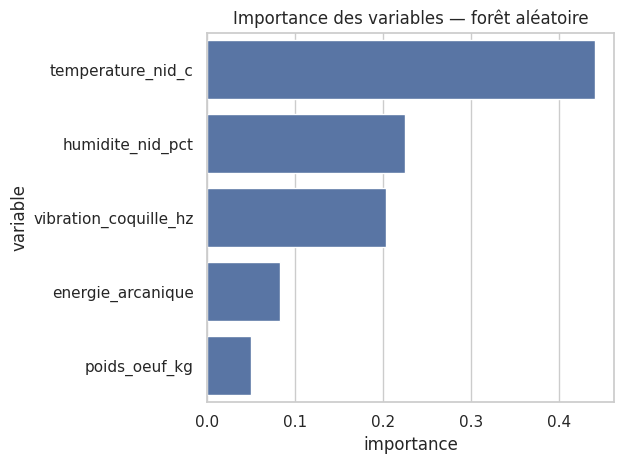

,modele,accuracy_cv_moyenne,accuracy_cv_ecart_type,f1_macro_cv_moyenne,f1_macro_cv_ecart_type
4,KNN,0.987434,0.010327,0.987483,0.010234
5,SVM RBF,0.985351,0.010726,0.985400,0.010647
3,Forêt aléatoire,0.985373,0.012522,0.985334,0.012545
1,Régression logistique,0.979101,0.009391,0.979143,0.009337
2,Arbre de décision,0.964474,0.012647,0.964517,0.012533
0,Dummy majoritaire,0.331930,0.002807,0.166138,0.001058


In [19]:
rf=clf_models["Forêt aléatoire"].named_steps["model"]
importance_clf=pd.DataFrame({"variable":FEATURES_CLF,"importance":rf.feature_importances_}).sort_values("importance",ascending=False)
display(importance_clf)
sns.barplot(data=importance_clf,x="importance",y="variable"); plt.title("Importance des variables — forêt aléatoire"); plt.tight_layout(); plt.show()
min_train=int(y_train_c.value_counts().min()); n_splits=min(5,min_train)
cv_clf_df=pd.DataFrame()
if n_splits>=2:
    cv=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=RANDOM_STATE); cvrows=[]
    for name,est in classifiers.items():
        pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("model",est)])
        scores=cross_validate(pipe,X_train_c,y_train_c,cv=cv,scoring={"accuracy":"accuracy","f1_macro":"f1_macro"})
        cvrows.append({"modele":name,"accuracy_cv_moyenne":scores["test_accuracy"].mean(),"accuracy_cv_ecart_type":scores["test_accuracy"].std(),"f1_macro_cv_moyenne":scores["test_f1_macro"].mean(),"f1_macro_cv_ecart_type":scores["test_f1_macro"].std()})
    cv_clf_df=pd.DataFrame(cvrows).sort_values("f1_macro_cv_moyenne",ascending=False); display(cv_clf_df)
else: print("Validation croisée stratifiée impossible : effectif de classe insuffisant.")

### Interprétation de l'importance des variables et de la validation croisée

L'analyse de l'importance des variables de la forêt aléatoire montre que la température du nid est la variable la plus importante (44,00 %), suivie de l'humidité (22,42 %) et des vibrations de la coquille (20,30 %). L'énergie arcanique (8,27 %) et le poids de l'œuf (5,00 %) présentent une importance plus faible dans ce modèle.

La validation croisée stratifiée confirme les bonnes performances des modèles. Le KNN obtient le meilleur F1-score macro moyen, avec 98,75 %, et une accuracy moyenne de 98,74 %. Le SVM RBF et la forêt aléatoire obtiennent également des scores élevés, proches de 98,5 %.

Le KNN est donc retenu comme meilleur candidat parmi les modèles testés, car il combine les meilleures performances moyennes et un temps d'exécution faible. Ces résultats restent liés à ce jeu de données et devront être confirmés sur de nouvelles observations.

## 7. Régression : estimer l’énergie arcanique

La cible est `energie_arcanique`. Les variables explicatives sont la température, l’humidité, le poids et les vibrations ; l’énergie n’est pas utilisée comme prédicteur. Les lignes sans énergie connue sont exclues de cette tâche. Les modèles sont DummyRegressor, régression linéaire, forêt aléatoire, KNN et HistGradientBoosting. MAE et RMSE mesurent l’erreur (plus bas = mieux) ; R² mesure la variance expliquée et peut être négatif.

Observations avec énergie connue : 599


,energie_arcanique
count,599.0
mean,74.939399
std,17.671432
min,25.4
25%,61.55
50%,77.5
75%,87.8
max,180.0


,modele,MAE,RMSE,R2,temps_s
0,KNN,8.138810,10.255108,0.553036,0.043180
1,Forêt aléatoire,8.530216,10.917624,0.493419,2.019343
2,HistGradientBoosting,9.008683,11.567559,0.431309,3.060026
3,Dummy moyenne,12.994377,15.565358,-0.029700,0.018099
4,Régression linéaire,10.495043,16.333270,-0.133806,0.080502


Meilleur selon RMSE test : KNN


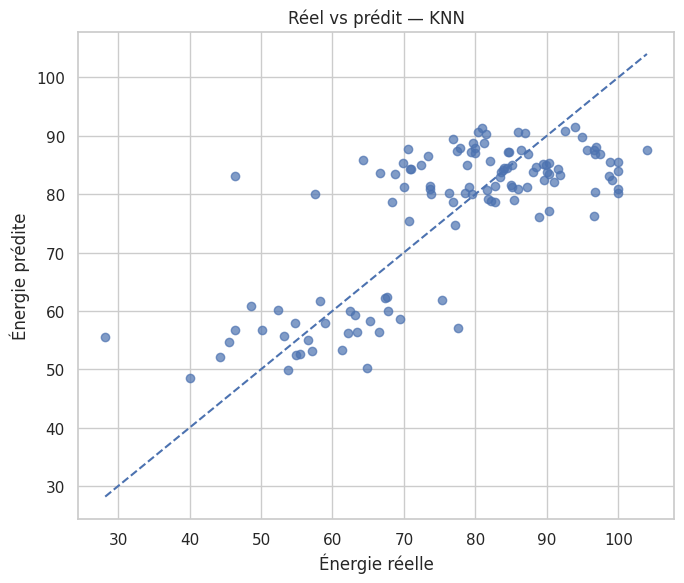

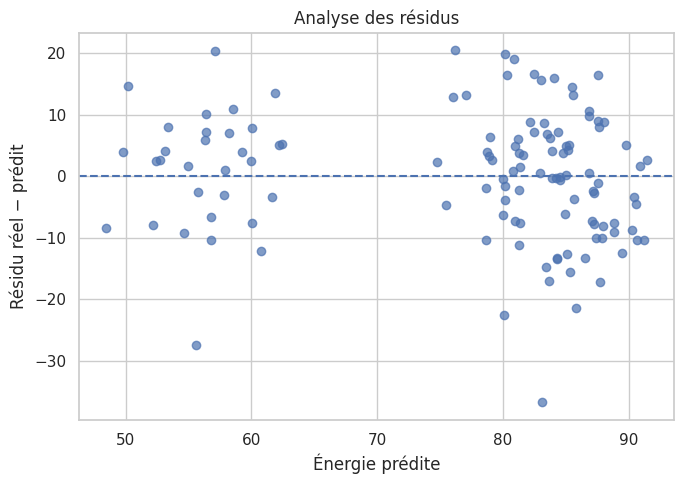

In [20]:
FEATURES_REG=["temperature_nid_c","humidite_nid_pct","poids_oeuf_kg","vibration_coquille_hz"]
df_reg=df_prepare.dropna(subset=["energie_arcanique"]).copy(); Xr=df_reg[FEATURES_REG]; yr=df_reg["energie_arcanique"]
print("Observations avec énergie connue :",len(yr)); display(yr.describe().to_frame("energie_arcanique"))
X_train_r,X_test_r,y_train_r,y_test_r=train_test_split(Xr,yr,test_size=.2,random_state=RANDOM_STATE)
regressors={"Dummy moyenne":DummyRegressor(strategy="mean"),"Régression linéaire":LinearRegression(),"Forêt aléatoire":RandomForestRegressor(n_estimators=250,random_state=RANDOM_STATE,min_samples_leaf=2,n_jobs=-1),"KNN":KNeighborsRegressor(n_neighbors=7),"HistGradientBoosting":HistGradientBoostingRegressor(random_state=RANDOM_STATE)}
reg_models={}; reg_preds={}; rows=[]
for name,est in regressors.items():
    pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("model",est)])
    t=time.perf_counter(); pipe.fit(X_train_r,y_train_r); duration=time.perf_counter()-t
    pred=pipe.predict(X_test_r); reg_models[name]=pipe; reg_preds[name]=pred
    rows.append({"modele":name,"MAE":mean_absolute_error(y_test_r,pred),"RMSE":np.sqrt(mean_squared_error(y_test_r,pred)),"R2":r2_score(y_test_r,pred),"temps_s":duration})
regression_results_df=pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True); display(regression_results_df)
meilleur_reg_nom=regression_results_df.iloc[0]["modele"]; pred_reg=reg_preds[meilleur_reg_nom]
print("Meilleur selon RMSE test :",meilleur_reg_nom)
lo=min(float(y_test_r.min()),float(np.min(pred_reg))); hi=max(float(y_test_r.max()),float(np.max(pred_reg)))
plt.figure(figsize=(7,6)); plt.scatter(y_test_r,pred_reg,alpha=.7); plt.plot([lo,hi],[lo,hi],"--"); plt.xlabel("Énergie réelle"); plt.ylabel("Énergie prédite"); plt.title("Réel vs prédit — "+meilleur_reg_nom); plt.tight_layout(); plt.show()
residus=y_test_r.to_numpy()-np.asarray(pred_reg)
plt.figure(figsize=(7,5)); plt.scatter(pred_reg,residus,alpha=.7); plt.axhline(0,linestyle="--"); plt.xlabel("Énergie prédite"); plt.ylabel("Résidu réel − prédit"); plt.title("Analyse des résidus"); plt.tight_layout(); plt.show()

### Interprétation des résultats de régression

Cinq modèles ont été comparés pour estimer l'énergie arcanique à partir de la température, de l'humidité, du poids et des vibrations de la coquille.

Le KNN obtient les meilleurs résultats sur le jeu de test, avec un MAE de 8,14, un RMSE de 10,26 et un R² de 0,553. L'erreur absolue moyenne est donc d'environ 8,14 unités d'énergie arcanique. Le modèle explique environ 55,3 % de la variabilité de la cible sur les observations testées.

La forêt aléatoire et HistGradientBoosting obtiennent des résultats intermédiaires. La régression linéaire fait moins bien que le modèle de référence selon le R².

Les graphiques réel-prédit et des résidus permettent d'examiner les écarts entre les estimations et les valeurs observées. Les résultats ne démontrent pas de relation de causalité entre les variables explicatives et l'énergie arcanique.

In [21]:
cv_reg_df=pd.DataFrame(); n_splits=min(5,len(X_train_r))
if n_splits>=2:
    cv=KFold(n_splits=n_splits,shuffle=True,random_state=RANDOM_STATE); rows=[]
    for name,est in regressors.items():
        pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("model",est)])
        scores=cross_validate(pipe,X_train_r,y_train_r,cv=cv,scoring={"mae":"neg_mean_absolute_error","rmse":"neg_root_mean_squared_error"})
        mae=-scores["test_mae"]; rmse=-scores["test_rmse"]
        rows.append({"modele":name,"MAE_cv_moyenne":mae.mean(),"MAE_cv_ecart_type":mae.std(),"RMSE_cv_moyenne":rmse.mean(),"RMSE_cv_ecart_type":rmse.std()})
    cv_reg_df=pd.DataFrame(rows).sort_values("RMSE_cv_moyenne"); display(cv_reg_df)
else: print("Pas assez de données pour une validation croisée.")

,modele,MAE_cv_moyenne,MAE_cv_ecart_type,RMSE_cv_moyenne,RMSE_cv_ecart_type
3,KNN,9.571144,0.246814,12.849865,1.439362
4,HistGradientBoosting,9.804368,0.539078,13.029101,1.661153
2,Forêt aléatoire,9.907826,0.565438,13.242946,1.835833
1,Régression linéaire,10.289184,0.490313,13.970629,1.187463
0,Dummy moyenne,14.564688,0.702123,18.151606,0.713363


## 8. Détection non supervisée des anomalies

L'analyse utilise les cinq variables numériques, dont l'énergie arcanique, sans utiliser l'identifiant ni le clan. Les valeurs manquantes sont imputées par la médiane et les variables sont standardisées. Isolation Forest et LOF utilisent contamination=0.05 comme hypothèse exploratoire, correspondant à environ 5 % de signalements attendus. La méthode IQR examine chaque variable séparément.
Sans étiquettes d'anomalies vérifiées, les résultats constituent des alertes à examiner et non des erreurs confirmées.

In [27]:
FEATURES_ANOM=NUM_COLS
Xanom=df_prepare[FEATURES_ANOM]
prep=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
Xa=prep.fit_transform(Xanom)
iso=IsolationForest(contamination=.05,random_state=RANDOM_STATE,n_estimators=250); iso_labels=iso.fit_predict(Xa)
lof=LocalOutlierFactor(n_neighbors=20,contamination=.05); lof_labels=lof.fit_predict(Xa)
iqr_flags=pd.Series(False,index=df_prepare.index); iqr_rows=[]
for c in FEATURES_ANOM:
    s=df_prepare[c].dropna(); q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr
    mask=((df_prepare[c]<lo)|(df_prepare[c]>hi)).fillna(False); iqr_flags |= mask
    iqr_rows.append({"variable":c,"borne_basse":lo,"borne_haute":hi,"candidats_IQR":int(mask.sum())})
anomaly_results=pd.DataFrame({"methode":["Isolation Forest","LOF","IQR (au moins une variable)"],"observations_signalees":[int((iso_labels==-1).sum()),int((lof_labels==-1).sum()),int(iqr_flags.sum())],"pourcentage":[round((iso_labels==-1).mean()*100,2),round((lof_labels==-1).mean()*100,2),round(iqr_flags.mean()*100,2)]})
display(anomaly_results); display(pd.DataFrame(iqr_rows))
anomaly_flags=pd.DataFrame({"isolation_forest":iso_labels==-1,"lof":lof_labels==-1,"iqr":iqr_flags},index=df_prepare.index)
anomaly_flags["nb_methodes"]=anomaly_flags.sum(axis=1)
print("Nombre signalé par plusieurs méthodes :",int((anomaly_flags["nb_methodes"]>=2).sum()))
# cols=[c for c in ["id_oeuf"]+FEATURES_ANOM+["clan_dragon"] if c in df_prepare.columns]
# anomalies_detail=df_prepare.loc[anomaly_flags["nb_methodes"]>0,cols].copy(); anomalies_detail["nb_methodes_signalement"]=anomaly_flags.loc[anomalies_detail.index,"nb_methodes"]
# display(anomalies_detail.sort_values("nb_methodes_signalement",ascending=False).head(30))
# Préparer le tableau détaillé des anomalies
cols = [
    c for c in ["id_oeuf"] + FEATURES_ANOM + ["clan_dragon"]
    if c in df_prepare.columns
]

anomalies_detail = df_prepare.loc[
    anomaly_flags["nb_methodes"] > 0, cols
].copy()

anomalies_detail["nb_methodes_signalement"] = anomaly_flags.loc[
    anomalies_detail.index, "nb_methodes"
]

# Distinguer les observations signalées par plusieurs méthodes
anomalies_multiples = anomalies_detail[
    anomalies_detail["nb_methodes_signalement"] >= 2
].sort_values("nb_methodes_signalement", ascending=False)

anomalies_uniques = anomalies_detail[
    anomalies_detail["nb_methodes_signalement"] == 1
]

print(
    "Observations signalées par au moins deux méthodes :",
    len(anomalies_multiples)
)
display(anomalies_multiples)

print(
    "Observations signalées par une seule méthode :",
    len(anomalies_uniques)
)
display(anomalies_uniques)

,methode,observations_signalees,pourcentage
0,Isolation Forest,30,5.0
1,LOF,30,5.0
2,IQR (au moins une variable),12,2.0


,variable,borne_basse,borne_haute,candidats_IQR
0,temperature_nid_c,-23.8000,129.2000,1
1,humidite_nid_pct,-13.8125,122.0875,0
2,energie_arcanique,22.1750,127.1750,2
3,poids_oeuf_kg,2.6850,7.2050,8
4,vibration_coquille_hz,-5.3000,39.5000,2


Nombre signalé par plusieurs méthodes : 19
Observations signalées par au moins deux méthodes : 19


,id_oeuf,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz,clan_dragon,nb_methodes_signalement
76,SYN-0014,47.8,46.6,84.4,38.0,29.3,Foudre,3
103,SYN-0075,25.8,59.8,38.3,2.2,10.4,Glace,3
254,SYN-0412,135.0,36.5,79.7,6.14,11.3,Feu,3
597,OEUF-057,27.3,72.0,57.4,4.55,250.0,Glace,3
253,SYN-0397,64.3,30.8,69.3,7.27,250.0,Feu,3
511,SYN-0167,63.8,54.2,180.0,4.79,25.2,Foudre,3
309,OEUF-068,44.0,51.2,180.0,3.79,27.6,Foudre,3
123,SYN-0231,-18.0,67.4,56.6,5.07,12.4,Glace,2
243,SYN-0100,70.4,21.4,95.2,4.42,6.4,Feu,2
138,SYN-0367,78.9,27.5,46.4,6.23,12.4,Feu,2


Observations signalées par une seule méthode : 27


,id_oeuf,temperature_nid_c,humidite_nid_pct,energie_arcanique,poids_oeuf_kg,vibration_coquille_hz,clan_dragon,nb_methodes_signalement
20,SYN-0114,24.0,77.3,39.1,5.88,14.1,Glace,1
27,SYN-0065,58.4,36.9,56.0,4.22,25.5,Foudre,1
48,SYN-0158,42.1,36.1,60.8,4.39,22.7,Foudre,1
50,SYN-0105,33.6,<NA>,44.2,5.01,14.1,Glace,1
96,SYN-0268,88.0,53.2,94.5,4.69,15.3,Feu,1
121,SYN-0179,45.6,29.8,67.0,4.31,19.4,Foudre,1
133,OEUF-089,43.7,30.9,79.9,3.51,30.2,Foudre,1
187,SYN-0383,53.1,33.7,82.2,6.04,28.1,Foudre,1
195,SYN-0284,54.7,42.1,60.0,4.95,27.2,Foudre,1
202,SYN-0402,39.8,90.9,44.7,3.52,7.1,Glace,1


### Interprétation des résultats de détection d'anomalies

Trois méthodes ont été utilisées pour repérer les observations atypiques : Isolation Forest, LOF et la méthode IQR. Isolation Forest et LOF ont chacune signalé 30 observations, soit 5 % du jeu de données, conformément au paramètre de contamination choisi. La méthode IQR a identifié 12 observations présentant au moins une valeur située en dehors des bornes statistiques.

Au total, **46 observations** ont été signalées par au moins une méthode :
- **19 observations** ont été signalées par au moins deux méthodes. Elles constituent les cas à examiner en priorité.
- **27 observations** ont été signalées par une seule méthode. Elles méritent également une vérification, mais les résultats sont moins convergents.

Certaines observations présentent des valeurs particulièrement atypiques, notamment un poids de 38 kg, des vibrations de 250 Hz, une température de 135 °C ou une énergie arcanique de 180.

Ces résultats montrent que les méthodes statistiques et non supervisées permettent d'identifier des données inhabituelles de différentes manières. Cependant, une anomalie détectée n'est pas nécessairement une erreur : elle peut représenter une observation rare mais valide. Aucune donnée ne doit donc être supprimée sans vérification complémentaire.

## 9. Benchmark, export et conclusion

Les métriques de classification et de régression ne sont pas comparables entre elles car les cibles diffèrent. Pour la classification, le F1 macro est l’indicateur principal ; pour la régression, le RMSE est complété par la MAE et R². Les temps sont indicatifs.

In [24]:
print("Classification — tri F1 macro"); display(classification_results_df)
print("Régression — tri RMSE"); display(regression_results_df)
print("Détection d’anomalies"); display(anomaly_results)

Classification — tri F1 macro


,modele,accuracy,precision_macro,rappel_macro,f1_macro,temps_s
0,KNN,0.983333,0.984127,0.983333,0.983323,0.116185
1,Forêt aléatoire,0.983333,0.984127,0.983333,0.983323,4.867429
2,SVM RBF,0.983333,0.984127,0.983333,0.983323,0.165897
3,Régression logistique,0.975000,0.975580,0.975000,0.974992,0.948430
4,Arbre de décision,0.966667,0.967643,0.966667,0.966862,0.311668
5,Dummy majoritaire,0.333333,0.111111,0.333333,0.166667,0.854221


Régression — tri RMSE


,modele,MAE,RMSE,R2,temps_s
0,KNN,8.138810,10.255108,0.553036,0.043180
1,Forêt aléatoire,8.530216,10.917624,0.493419,2.019343
2,HistGradientBoosting,9.008683,11.567559,0.431309,3.060026
3,Dummy moyenne,12.994377,15.565358,-0.029700,0.018099
4,Régression linéaire,10.495043,16.333270,-0.133806,0.080502


Détection d’anomalies


,methode,observations_signalees,pourcentage
0,Isolation Forest,30,5.0
1,LOF,30,5.0
2,IQR (au moins une variable),12,2.0


### Synthèse comparative des modèles

**Classification :** KNN, la forêt aléatoire et le SVM RBF obtiennent des performances très proches. KNN est retenu grâce à ses bons résultats en validation croisée et à son temps d'exécution réduit.

**Régression :** KNN présente les meilleures performances parmi les modèles testés. La prédiction de l'énergie arcanique reste néanmoins moins précise que la classification des clans.

**Détection des anomalies :** les trois méthodes identifient des observations atypiques, mais leurs résultats ne suffisent pas à confirmer des erreurs dans les données.

Les métriques doivent être interprétées séparément selon la tâche. Les temps d'exécution sont indicatifs et dépendent de l'environnement utilisé.

## 10. Export des résultats
Les fichiers seront enregistrés dans `outputs/`

In [25]:
OUT=Path("outputs"); OUT.mkdir(exist_ok=True)
df_prepare.to_csv(OUT/"dragons_prepares.csv",index=False)
rapport_qualite.to_csv(OUT/"rapport_qualite.csv",index=False)
classification_results_df.to_csv(OUT/"benchmark_classification.csv",index=False)
regression_results_df.to_csv(OUT/"benchmark_regression.csv",index=False)
anomaly_results.to_csv(OUT/"benchmark_anomalies.csv",index=False)
anomaly_flags.to_csv(OUT/"indicateurs_anomalies.csv",index=True)
anomalies_detail.to_csv(OUT/"observations_signalees.csv",index=True)
if not cv_clf_df.empty: cv_clf_df.to_csv(OUT/"validation_croisee_classification.csv",index=False)
if not cv_reg_df.empty: cv_reg_df.to_csv(OUT/"validation_croisee_regression.csv",index=False)
print("Exports créés dans",OUT.resolve()); print(sorted(p.name for p in OUT.iterdir()))

Exports créés dans /home/chaima/projets/TP_Dragons/outputs
['benchmark_anomalies.csv', 'benchmark_classification.csv', 'benchmark_regression.csv', 'dragons_prepares.csv', 'indicateurs_anomalies.csv', 'observations_signalees.csv', 'rapport_qualite.csv', 'validation_croisee_classification.csv', 'validation_croisee_regression.csv']


## 11. Conclusion générale

### Qualité des données

Le fichier initial contenait 607 lignes et 7 colonnes. Après le nettoyage, il reste 600 lignes et aucun doublon complet. Les noms des colonnes et des clans ont été harmonisés, et les types des mesures ont été vérifiés. Il reste cependant quelques valeurs manquantes, notamment dans l’humidité, les vibrations et les identifiants. Un clan est également manquant. Ces valeurs ont été conservées et les valeurs numériques manquantes sont prises en charge par l’imputation dans les modèles.

### Classification

KNN, la forêt aléatoire et le SVM donnent les meilleurs résultats sur les données de test, avec un F1 macro de 98,33 %. Ces résultats sont bien meilleurs que ceux du modèle de référence DummyClassifier, qui obtient une accuracy de 33,33 %. La validation croisée confirme également les bonnes performances de KNN. Il semble donc adapté pour prédire le clan d’un dragon à partir des caractéristiques de son œuf.

### Régression

KNN donne également les meilleurs résultats pour prédire l’énergie arcanique, avec un RMSE de 10,26, une MAE de 8,14 et un R² de 0,553. Le modèle explique environ 55 % des variations observées dans les données de test. Les résultats sont encourageants, mais les prédictions restent imparfaites et pourraient être améliorées.

### Anomalies et limites

Les méthodes Isolation Forest et LOF ont chacune signalé 30 observations, tandis que la méthode IQR en a identifié 12. Ces valeurs doivent être vérifiées, car une anomalie détectée n’est pas forcément une erreur.

Les résultats dépendent aussi des données disponibles et du découpage entre entraînement et test. Il faudrait notamment vérifier si les identifiants répétés correspondent à plusieurs mesures d’un même œuf. Dans ce cas, il serait préférable de séparer les données par identifiant pour évaluer les modèles plus correctement.

### Bilan

Les résultats sont satisfaisants pour la classification, tandis que la prédiction de l’énergie arcanique reste à améliorer.

## 12. Contrôle final

In [26]:
print("Dimensions finales :",df_prepare.shape)
print("Doublons complets restants :",int(df_prepare.duplicated().sum()))
print("Valeurs manquantes :"); display(df_prepare.isna().sum().to_frame("nombre"))
print("Types :"); display(df_prepare.dtypes.to_frame("type"))
print("Clans :"); display(df_prepare["clan_dragon"].value_counts(dropna=False).to_frame("effectif"))

Dimensions finales : (600, 7)
Doublons complets restants : 0
Valeurs manquantes :


,nombre
id_oeuf,2
temperature_nid_c,0
humidite_nid_pct,4
energie_arcanique,1
poids_oeuf_kg,1
vibration_coquille_hz,4
clan_dragon,1


Types :


,type
id_oeuf,object
temperature_nid_c,Float64
humidite_nid_pct,Float64
energie_arcanique,Float64
poids_oeuf_kg,Float64
vibration_coquille_hz,Float64
clan_dragon,object


Clans :


,effectif
clan_dragon,
Glace,200
Foudre,200
Feu,199
NaN,1
